# 05 - State & Regional Concentration ("Where")

Which states/regions rely most on coal and how that is shifting. Uses STATE rows only (excludes regions + U.S. Total) to avoid double counting.

In [1]:
import sys, os
ROOT = os.getcwd() if os.path.exists(os.path.join(os.getcwd(), "src")) else os.path.dirname(os.getcwd())
sys.path.insert(0, ROOT)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
DATA = os.path.join(ROOT, "data", "eia_coal_consumption_quality_2020_2025.csv")
CHARTS = os.path.join(ROOT, "charts")
os.makedirs(CHARTS, exist_ok=True)
print("ROOT:", ROOT)


ROOT: C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26


In [2]:
def savefig(name):
    p = os.path.join(CHARTS, name)
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print('saved', p)
    plt.show()


In [3]:
from src.data import load_coal_data, CLEAN_SECTOR_BREAKDOWN
from src.taxonomy import add_location_level, filter_location, total_coal_use
from src.clean import clean
df = add_location_level(clean(load_coal_data(DATA)))
states = filter_location(df, 'state')
regions = filter_location(df, 'region')
# sanity: no US or region codes leaked into the state frame
assert 'US' not in states['location'].unique()
assert not set(states['location'].unique()) & set(regions['location'].unique())
print('state-level rows:', len(states))

state-level rows: 1291


In [4]:
# State total consumption per state-year (clean breakdown summed)
st_tot = (states[states['sector'].isin(CLEAN_SECTOR_BREAKDOWN)]
         .groupby(['period', 'location'])['consumption'].sum().reset_index())
nat = total_coal_use(df, 'national')  # national total per year
# latest FULL year for ranking = 2024 (2025 preliminary)
latest = st_tot[st_tot['period'] == 2024].sort_values('consumption', ascending=False).copy()
latest['share_of_us_pct'] = (latest['consumption'] / nat.loc[2024] * 100).round(2)
latest.head(12)

,period,location,consumption,share_of_us_pct
241,2024,TX,47017182.00,11.44
213,2024,IN,25826652.78,6.28
225,2024,ND,25179135.00,6.13
221,2024,MO,23712802.00,5.77
215,2024,KY,22329054.00,5.43
212,2024,IL,18614032.00,4.53
246,2024,WV,18239020.00,4.44
247,2024,WY,17138985.00,4.17
219,2024,MI,15985727.00,3.89
232,2024,OH,15692385.00,3.82


In [5]:
# Concentration: top-5 states' share of national over time
wide = st_tot.pivot_table(index='period', columns='location', values='consumption')
top5_share = wide[latest['location'].head(5).tolist()].sum(axis=1) / nat * 100
print('Top-5 states share of U.S. coal use (%):')
print(top5_share.round(1).to_string())

Top-5 states share of U.S. coal use (%):
period
2020    34.5
2021    33.1
2022    33.7
2023    34.6
2024    35.1
2025    34.3


saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\05_top_states_2024.png


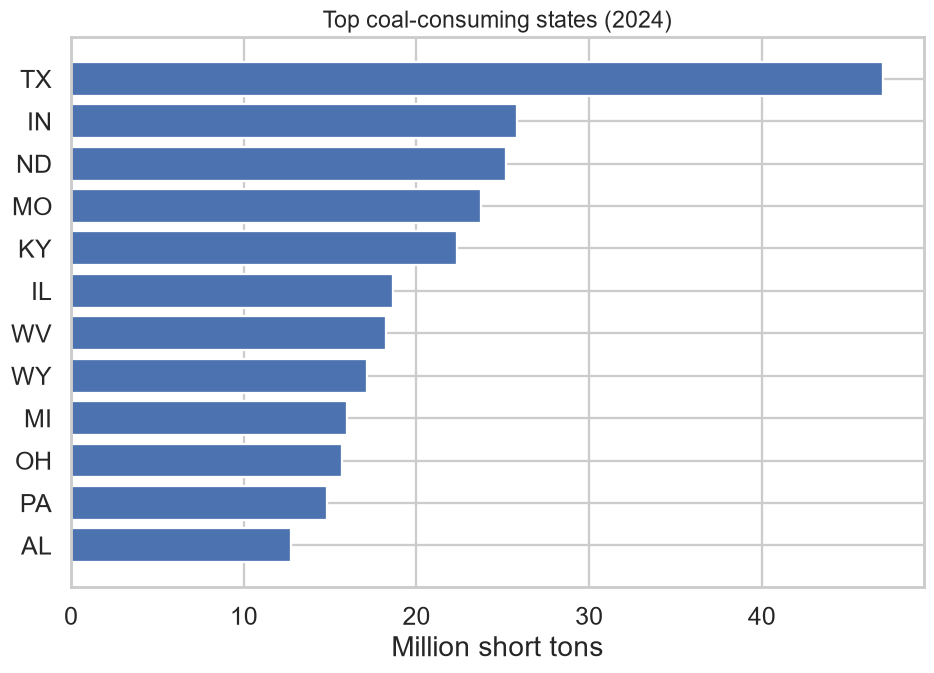

In [6]:
top12 = latest.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(top12['location'], top12['consumption'] / 1e6, color='#4c72b0')
ax.set_title('Top coal-consuming states (2024)', fontsize=15)
ax.set_xlabel('Million short tons')
savefig('05_top_states_2024.png')

saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\05_regional_trends.png


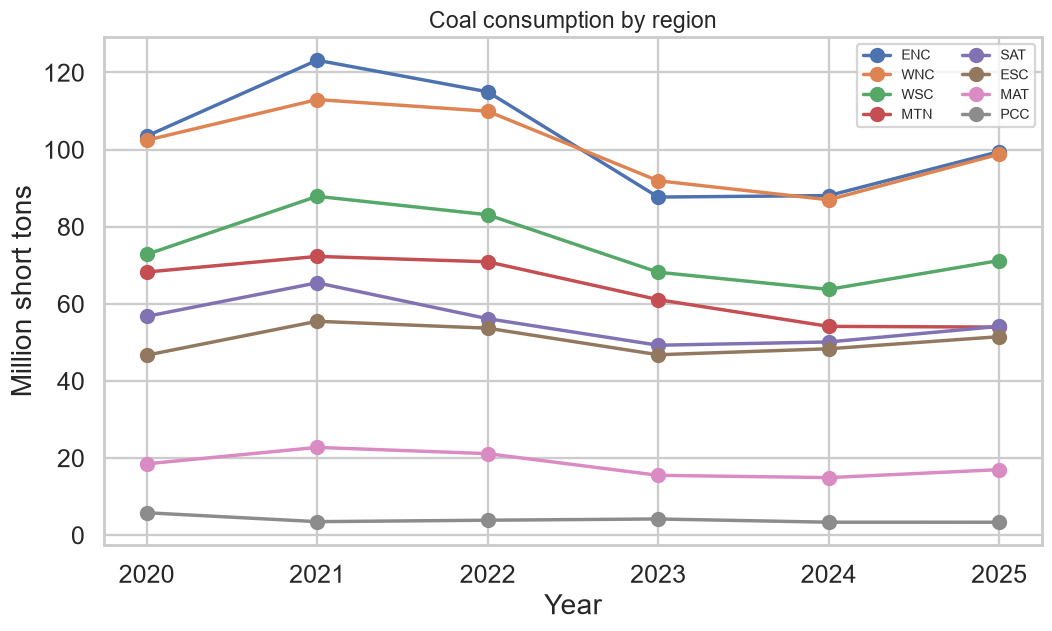

In [7]:
# Regional trend lines (region-level rows, clean breakdown)
reg_tot = (regions[regions['sector'].isin(CLEAN_SECTOR_BREAKDOWN)]
           .groupby(['period', 'location'])['consumption'].sum().reset_index())
reg_piv = (reg_tot.pivot_table(index='period', columns='location', values='consumption') / 1e6)
# keep regions with meaningful volume
keep = reg_piv.mean().sort_values(ascending=False).head(8).index
reg_piv = reg_piv[keep]
fig, ax = plt.subplots(figsize=(11, 6))
for c in reg_piv.columns:
    ax.plot(reg_piv.index, reg_piv[c], marker='o', label=c)
ax.set_title('Coal consumption by region', fontsize=15)
ax.set_xlabel('Year'); ax.set_ylabel('Million short tons'); ax.legend(fontsize=9, ncol=2)
savefig('05_regional_trends.png')

saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\05_state_movers_2020_2024.png


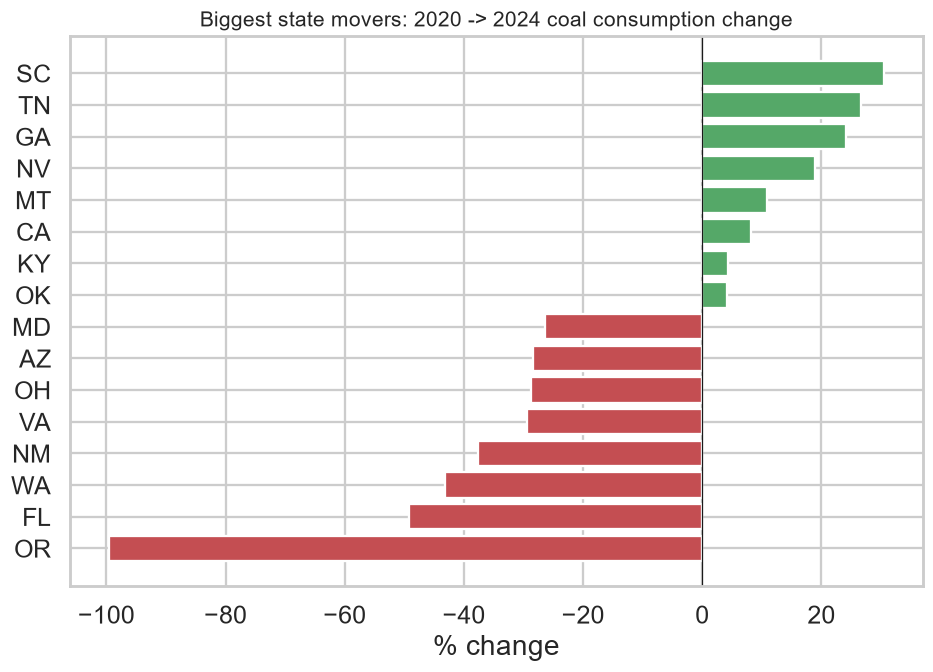

In [8]:
# Rising vs falling states: 2020 -> 2024 change
chg = ((wide.loc[2024] - wide.loc[2020]) / wide.loc[2020] * 100)
# restrict to states with meaningful 2020 base to avoid noise
chg = chg[(wide.loc[2020] > 1_000_000) & chg.notna()].sort_values()
movers = pd.concat([chg.head(8), chg.tail(8)])
fig, ax = plt.subplots(figsize=(10, 6.5))
colors = ['#c44e52' if v < 0 else '#55a868' for v in movers.values]
ax.barh(movers.index, movers.values, color=colors)
ax.set_title('Biggest state movers: 2020 -> 2024 coal consumption change', fontsize=14)
ax.set_xlabel('% change'); ax.axvline(0, color='k', lw=0.8)
savefig('05_state_movers_2020_2024.png')

In [9]:
# Cross-check: state sums vs region rows (document gaps)
from src.taxonomy import check_regions_vs_states
regfails = check_regions_vs_states(df, tol_pct=0.5)
print('region-vs-state mismatches > 0.5%:', len(regfails))
if not regfails.empty:
    print(regfails.head(10).to_string(index=False))

region-vs-state mismatches > 0.5%: 18
region  period  sector  region_value  states_sum  pct_diff
   SAT    2020       2     5588268.0   7088442.0     26.85
   SAT    2020      94     6341315.0   7841489.0     23.66
   SAT    2020      98    53093538.0  54593712.0      2.83
   SAT    2021       2     7591909.0   9223204.0     21.49
   SAT    2021      94     8406252.0  10037547.0     19.41
   SAT    2021      98    61523095.0  63154390.0      2.65
   SAT    2022       2     7071662.0   8587867.0     21.44
   SAT    2022      94     7923796.0   9440001.0     19.13
   SAT    2022      98    53138341.0  54654546.0      2.85
   SAT    2023       2     4447779.0   5792427.0     30.23


**Takeaways**
- Coal use is highly concentrated in a few states (top-5 hold a large share of national consumption); the most-exposed states are the investment-relevant geographies.
- Some states are cutting coal fast while a few still grow - the diverging-bar chart separates clear winners (decliners) from laggards.
- Region-vs-state sums mostly reconcile; any gaps are documented as a data limitation rather than double-counted.